# Détection de caractéristiques

In [1]:
import numpy as np
import skimage.io as io
import matplotlib.pyplot as plt
from skimage.feature import canny
from skimage.transform import hough_line, hough_line_peaks

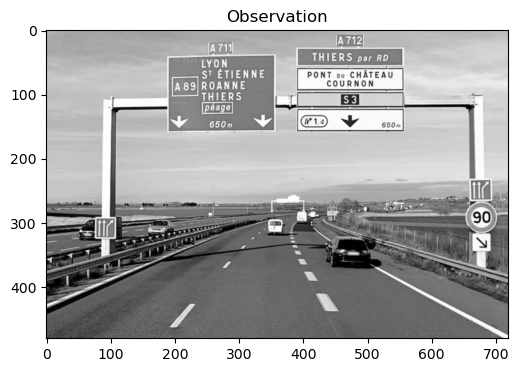

In [2]:
img = io.imread('../_static/route1.jpg')
fig, axs = plt.subplots(1, 1, figsize=(8,4))
axs.imshow(img, "gray")
axs.set_title("Observation")
plt.show()

## Détection de contours (détecteur de Canny)

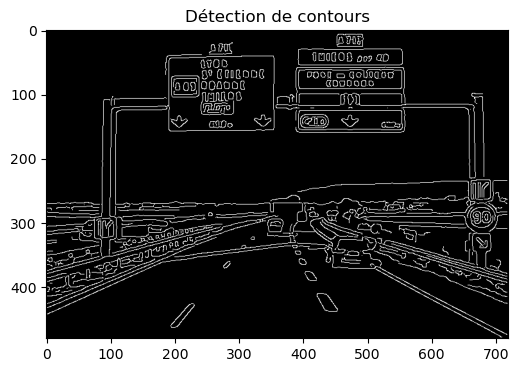

In [3]:
contours = canny(img, sigma=2)
fig, axs = plt.subplots(1, 1, figsize=(8,4))
axs.imshow(contours, "gray")
axs.set_title("Détection de contours")
plt.show()

## Influence de $\sigma$

Le paramètre $\sigma$ (`sigma`) est l'écart-type du filtre gaussien appliqué sur l'image en toute première étape du détecteur de Canny,
dont l'objectif est de flouter légèrement l'image pour réduire le bruit.

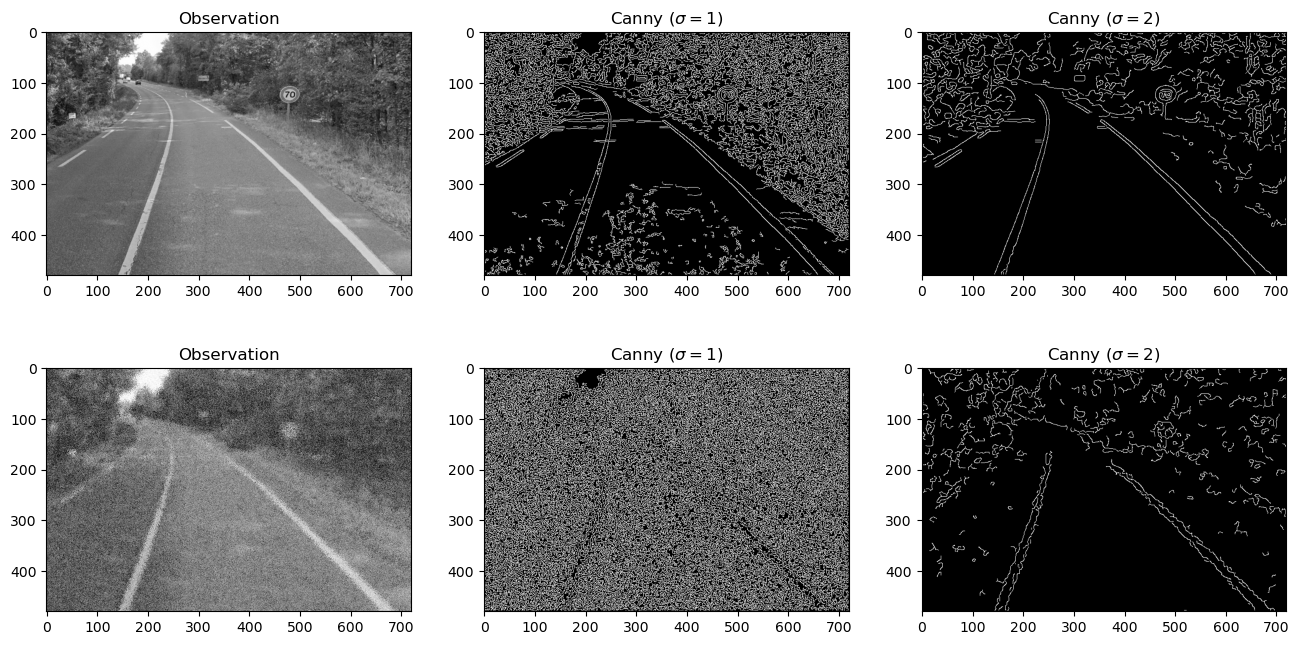

In [4]:
# Effet de sigma
images = ["route2.jpg", "route2-bruit.jpg"]
fig, axs = plt.subplots(2, 3, figsize=(16,8))
for k in range(len(images)):
    x = io.imread(f'../_static/{images[k]}')
    y1 = canny(x, sigma=1)
    y2 = canny(x, sigma=2)
    axs[k,0].imshow(x, "gray")
    axs[k,0].set_title("Observation")
    axs[k,1].imshow(y1, "gray")
    axs[k,1].set_title("Canny ($\\sigma=1$)")
    axs[k,2].imshow(y2, "gray")
    axs[k,2].set_title("Canny ($\\sigma=2$)")
plt.show()

## Application du masque sur les contours détectés

In [5]:
# Masque
if True:

    # Chargement du masque
    mask = io.imread("../_static/route-masque.png")

else:

    # Sinon : création du masque

    # Initialisation
    R, C = contours.shape
    r, c = np.arange(R), np.arange(C)
    cols, rows = np.meshgrid(c, r)

    # Définition du contour
    mask = np.ones((R,C))
    mask = np.where( rows>250, mask, 0 )
    mask = np.where( rows >  .7 * cols - 70, mask, 0 )
    mask = np.where( rows > -.7 * cols + 440, mask, 0 )
    
    # Enregistrement
    import skimage as ski
    mask_save = ski.util.img_as_ubyte(mask)
    io.imsave("route-masque.png", mask_save)

    # Affichage
    plt.figure()
    plt.imshow(mask+contours, "gray")#, origin='lower')
    plt.show()

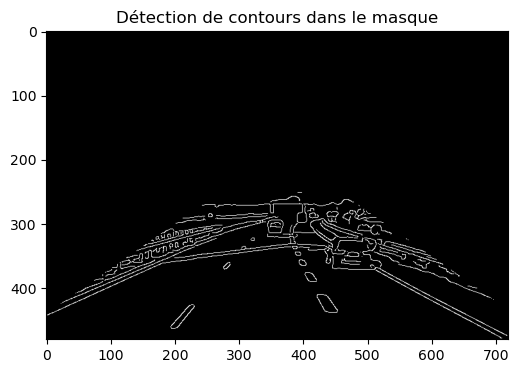

In [6]:
road_contours = contours * mask
fig, axs = plt.subplots(1, 1, figsize=(8,4))
axs.imshow(road_contours, "gray")
axs.set_title("Détection de contours dans le masque")
plt.show()

## Détection de lignes (transformée de Hough)

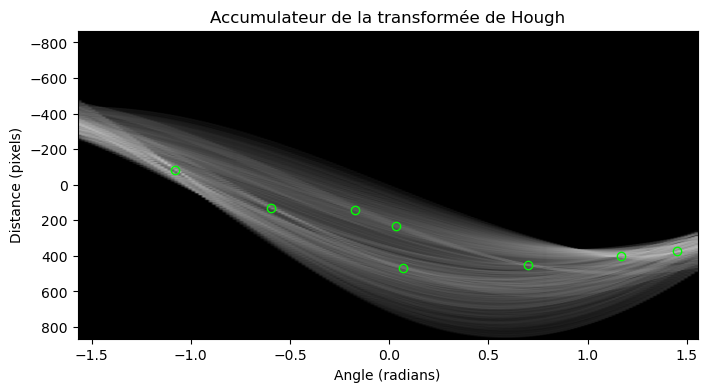

In [7]:
accumulator, angle, dist  = hough_line(road_contours)
peaks, angles, dists = hough_line_peaks(accumulator, angle, dist, threshold=.1*accumulator.max(), min_distance = 100)

# Affichage
axes = (angle[0], angle[-1], dist[-1], dist[0])
plt.figure(figsize=(8,4))
plt.imshow(np.log(accumulator+5), cmap="gray", extent=axes, aspect="auto")
plt.xlabel('Angle (radians)')
plt.ylabel('Distance (pixels)')
plt.title("Accumulateur de la transformée de Hough")
plt.plot(angles, dists, marker='o', markeredgecolor='lime', markerfacecolor="none", linestyle="none")
plt.show()

Affichage des lignes détectées. Là aussi je donnerai de gros indices pour l'affichage.

redonner la géométrie de theta et dist pour tracer les lignes
faire un filtre pour ne conserver que deux lignes par ex (à partir de la valeur de peaks)

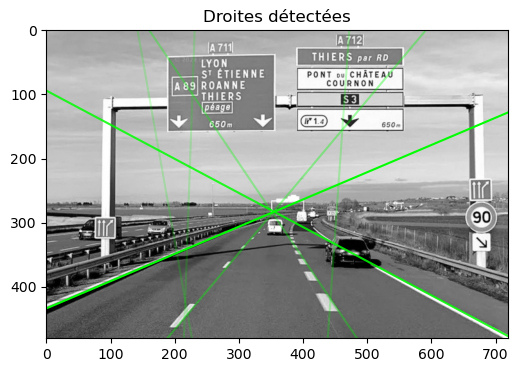

In [8]:
# Image
R, C = img.shape
fig, axs = plt.subplots(1, 1, figsize=(8,4))
axs.imshow(img, "gray")

# Transparence fonction de l'intensité du pic détecté
alphas = .09 + .9 * peaks / np.max(peaks)

# Trace chaque ligne
for k in range(len(peaks)):

    # Angle, distance et transparence
    angle = angles[k]
    dist  = dists[k]
    alpha = alphas[k]

    # N'affiche pas les lignes verticales (angle < 1e-3) ou trop horizontales (angle trop proche de ± 90°)
    if np.abs(angle) > 1e-3 and np.abs(angle) < .8*np.pi/2:
            
        # Coordonnée de la ligne
        x0 = 0
        y0 = dist / np.sin(angle)
        x1 = C
        y1 = (dist - x1*np.cos(angle)) / np.sin(angle)
        
        # Tracé de la ligne
        plt.plot((x0, x1), (y0, y1), color='lime', alpha=alpha)

# Axes
plt.axis((0,C,R,0))
axs.set_title("Droites détectées")
plt.show()

## Exemples sur d'autres images

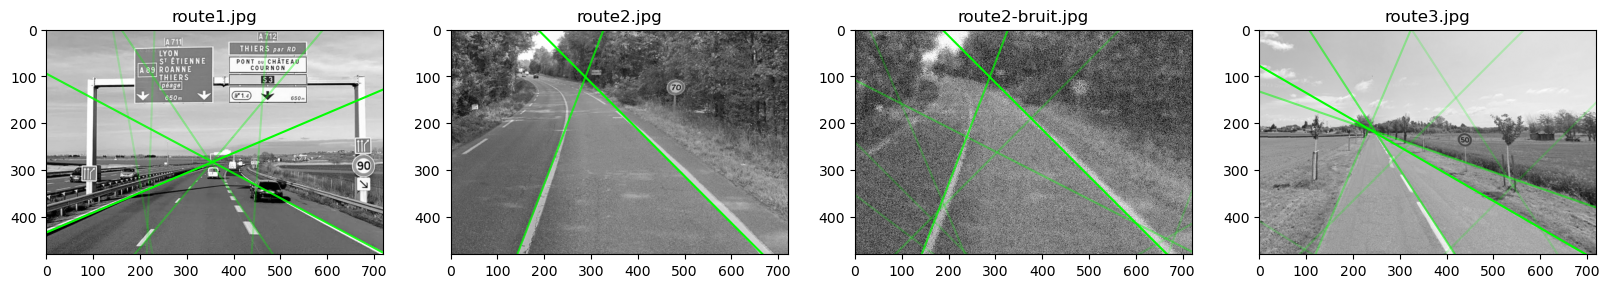

In [9]:
filenames = [
    "route1.jpg",
    "route2.jpg",
    "route2-bruit.jpg",
    "route3.jpg",
]
N = len(filenames)
fig, axs = plt.subplots(1, N, figsize=(20,4))

for n in range(N):

    # Chargement et traitements
    img = io.imread(f"../_static/{filenames[n]}")
    contours = canny(img, sigma=2)
    road_contours = contours * mask
    accumulator, angle, dist  = hough_line(road_contours)
    peaks, angles, dists = hough_line_peaks(accumulator, angle, dist, threshold=.1*accumulator.max(), min_distance = 100)
    R, C = img.shape
    
    # Affichage
    axs[n].imshow(img, "gray")
    alphas = .09 + .9 * peaks / np.max(peaks)
    for k in range(len(peaks)):
    
        # Angle, distance et transparence
        angle = angles[k]
        dist  = dists[k]
        alpha = alphas[k]
    
        # N'affiche pas les lignes verticales (angle < 1e-3) ou trop horizontales (angle trop proche de ± 90°)
        if np.abs(angle) > 1e-3 and np.abs(angle) < .8*np.pi/2:
                
            # Coordonnée de la ligne
            x0 = 0
            y0 = dist / np.sin(angle)
            x1 = C
            y1 = (dist - x1*np.cos(angle)) / np.sin(angle)
            
            # Tracé de la ligne
            axs[n].plot((x0, x1), (y0, y1), color='lime', alpha=alpha)
    
    # Axes
    axs[n].axis((0,C,R,0))
    axs[n].set_title(filenames[n])

plt.show()